# European Soccer Match Outcome Analysis

**IT3091 Machine Learning | Group 2026-DS-59**

This notebook contains the code for dataset loading, EDA, data quality checks, preprocessing, feature engineering, and feature selection. Business interpretation and recommendations will be documented in the report.

## 2.1 Project Environment Setup

In [ ]:
# Connect Google Drive (Google Colab)
from google.colab import drive
drive.mount('/content/drive')

import os
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Update this path to the location of database.sqlite in your Google Drive.
DB_PATH = "/content/drive/MyDrive/Y3S1/Assignment/database.sqlite"

if not os.path.exists(DB_PATH):
    raise FileNotFoundError(
        f"Database not found: {DB_PATH}. Update DB_PATH to the correct Google Drive location."
    )

print("Database found:", DB_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Database found: /content/drive/MyDrive/Y3S1/Assignment/database.sqlite


## 2.2 Database Connection

In [ ]:
conn = sqlite3.connect(DB_PATH)

print("Database connection established successfully.")

Database connection established successfully.


In [ ]:
integrity_result = conn.execute("PRAGMA integrity_check;").fetchone()

print("Database integrity check:", integrity_result[0])

Database integrity check: ok


## 3. Dataset and Database Understanding

In [ ]:
tables = pd.read_sql("""
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
""", conn)

tables

,name
0,Country
1,League
2,Match
3,Player
4,Player_Attributes
5,Team
6,Team_Attributes
7,sqlite_sequence


In [ ]:
match_df = pd.read_sql("SELECT * FROM Match", conn)

print("Number of rows:", match_df.shape[0])
print("Number of columns:", match_df.shape[1])

Number of rows: 25979
Number of columns: 115


In [ ]:
print(match_df.columns.tolist())

['id', 'country_id', 'league_id', 'season', 'stage', 'date', 'match_api_id', 'home_team_api_id', 'away_team_api_id', 'home_team_goal', 'away_team_goal', 'home_player_X1', 'home_player_X2', 'home_player_X3', 'home_player_X4', 'home_player_X5', 'home_player_X6', 'home_player_X7', 'home_player_X8', 'home_player_X9', 'home_player_X10', 'home_player_X11', 'away_player_X1', 'away_player_X2', 'away_player_X3', 'away_player_X4', 'away_player_X5', 'away_player_X6', 'away_player_X7', 'away_player_X8', 'away_player_X9', 'away_player_X10', 'away_player_X11', 'home_player_Y1', 'home_player_Y2', 'home_player_Y3', 'home_player_Y4', 'home_player_Y5', 'home_player_Y6', 'home_player_Y7', 'home_player_Y8', 'home_player_Y9', 'home_player_Y10', 'home_player_Y11', 'away_player_Y1', 'away_player_Y2', 'away_player_Y3', 'away_player_Y4', 'away_player_Y5', 'away_player_Y6', 'away_player_Y7', 'away_player_Y8', 'away_player_Y9', 'away_player_Y10', 'away_player_Y11', 'home_player_1', 'home_player_2', 'home_player_

In [ ]:
match_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25979 entries, 0 to 25978
Columns: 115 entries, id to BSA
dtypes: float64(96), int64(9), object(10)
memory usage: 22.8+ MB


In [ ]:
pd.set_option("display.max_columns", 120)
match_df.head(3)

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,home_player_X1,home_player_X2,home_player_X3,home_player_X4,home_player_X5,home_player_X6,home_player_X7,home_player_X8,home_player_X9,home_player_X10,home_player_X11,away_player_X1,away_player_X2,away_player_X3,away_player_X4,away_player_X5,away_player_X6,away_player_X7,away_player_X8,away_player_X9,away_player_X10,away_player_X11,home_player_Y1,home_player_Y2,home_player_Y3,home_player_Y4,home_player_Y5,home_player_Y6,home_player_Y7,home_player_Y8,home_player_Y9,home_player_Y10,home_player_Y11,away_player_Y1,away_player_Y2,away_player_Y3,away_player_Y4,away_player_Y5,away_player_Y6,away_player_Y7,away_player_Y8,away_player_Y9,away_player_Y10,away_player_Y11,home_player_1,home_player_2,home_player_3,home_player_4,home_player_5,home_player_6,home_player_7,home_player_8,home_player_9,home_player_10,home_player_11,away_player_1,away_player_2,away_player_3,away_player_4,away_player_5,away_player_6,away_player_7,away_player_8,away_player_9,away_player_10,away_player_11,goal,shoton,shotoff,foulcommit,card,cross,corner,possession,B365H,B365D,B365A,BWH,BWD,BWA,IWH,IWD,IWA,LBH,LBD,LBA,PSH,PSD,PSA,WHH,WHD,WHA,SJH,SJD,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.73,3.4,5.00,1.75,3.35,4.20,1.85,3.2,3.5,1.8,3.3,3.75,NaN,NaN,NaN,1.70,3.30,4.33,1.90,3.3,4.0,1.65,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,1.95,3.2,3.60,1.80,3.30,3.95,1.90,3.2,3.5,1.9,3.2,3.50,NaN,NaN,NaN,1.83,3.30,3.60,1.95,3.3,3.8,2.00,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,2.38,3.3,2.75,2.40,3.30,2.55,2.60,3.1,2.3,2.5,3.2,2.50,NaN,NaN,NaN,2.50,3.25,2.40,2.63,3.3,2.5,2.35,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75


## 4. Data Dictionary

In [ ]:
variable_dictionary = pd.DataFrame({
    "Variable": match_df.columns,
    "Data Type": match_df.dtypes.astype(str).values,
    "Missing Values": match_df.isnull().sum().values,
    "Unique Values": match_df.nunique().values
})

variable_dictionary

,Variable,Data Type,Missing Values,Unique Values
0,id,int64,0,25979
1,country_id,int64,0,11
2,league_id,int64,0,11
3,season,object,0,8
4,stage,int64,0,38
...,...,...,...,...
110,GBD,float64,11817,84
111,GBA,float64,11817,172
112,BSH,float64,11818,101
113,BSD,float64,11818,59


In [ ]:
variable_groups = {
    "Match Identification": [
        "id", "match_api_id", "country_id", "league_id"
    ],

    "Match Information": [
        "season", "stage", "date"
    ],

    "Team Information": [
        "home_team_api_id", "away_team_api_id"
    ],

    "Match Outcome / Goals": [
        "home_team_goal", "away_team_goal"
    ],

    "Player Line-up Information": [
        col for col in match_df.columns
        if "player_" in col
    ],

    "Match Event Statistics": [
        "goal", "shoton", "shotoff", "foulcommit",
        "card", "cross", "corner", "possession"
    ],

    "Betting Odds": [
        col for col in match_df.columns
        if col in [
            "B365H", "B365D", "B365A",
            "BWH", "BWD", "BWA",
            "IWH", "IWD", "IWA",
            "LBH", "LBD", "LBA",
            "PSH", "PSD", "PSA",
            "WHH", "WHD", "WHA",
            "SJH", "SJD", "SJA",
            "VCH", "VCD", "VCA",
            "GBH", "GBD", "GBA",
            "BSH", "BSD", "BSA"
        ]
    ]
}

for group, variables in variable_groups.items():
    print(f"\n{group}: {len(variables)} variables")


Match Identification: 4 variables

Match Information: 3 variables

Team Information: 2 variables

Match Outcome / Goals: 2 variables

Player Line-up Information: 66 variables

Match Event Statistics: 8 variables

Betting Odds: 30 variables


### Data Dictionary with Descriptions

In [ ]:
bookmakers = {"B365": "Bet365", "BW": "Bet&Win", "IW": "Interwetten", "LB": "Ladbrokes", "PS": "Pinnacle",
              "WH": "William Hill", "SJ": "Stan James", "VC": "VC Bet", "GB": "Gamebookers", "BS": "Blue Square"}
side_name = {"home": "home", "away": "away"}

def describe_column(c):
    fixed = {
        "id": ("Internal row number", "n/a (identifier)"),
        "country_id": ("Country of the league", "Before match"),
        "league_id": ("League of the match", "Before match"),
        "season": ("Season label, e.g. 2008/2009", "Before match"),
        "stage": ("Round / matchday number within the season", "Before match"),
        "date": ("Date of the match", "Before match"),
        "match_api_id": ("Unique match identifier", "n/a (identifier)"),
        "home_team_api_id": ("Home team identifier", "Before match"),
        "away_team_api_id": ("Away team identifier", "Before match"),
        "home_team_goal": ("Goals scored by the home team (full time)", "After match (target source)"),
        "away_team_goal": ("Goals scored by the away team (full time)", "After match (target source)"),
        "goal": ("XML log of goals scored", "During/after match"),
        "shoton": ("XML log of shots on target", "During/after match"),
        "shotoff": ("XML log of shots off target", "During/after match"),
        "foulcommit": ("XML log of fouls committed", "During/after match"),
        "card": ("XML log of cards", "During/after match"),
        "cross": ("XML log of crosses", "During/after match"),
        "corner": ("XML log of corners", "During/after match"),
        "possession": ("XML log of possession", "During/after match"),
    }
    if c in fixed: return fixed[c]
    m = re.match(r"(home|away)_player_(X|Y)?(\d+)$", c)
    if m:
        side, axis, n = m.groups()
        if axis: return (f"{axis} pitch coordinate of {side} line-up player {n}", "At kick-off (line-up)")
        return (f"Player identifier of {side} starting player {n}", "At kick-off (line-up)")
    m = re.match(r"([A-Z]+\d*)(H|D|A)$", c)
    if m and m.group(1) in bookmakers:
        res = {"H": "home win", "D": "draw", "A": "away win"}[m.group(2)]
        return (f"{bookmakers[m.group(1)]} decimal odds for a {res}", "Before match")
    return ("", "")

import re
dd = variable_dictionary.copy()
dd["Description"] = [describe_column(c)[0] for c in dd["Variable"]]
dd["Known when?"] = [describe_column(c)[1] for c in dd["Variable"]]
print("Variables without a description:", (dd["Description"] == "").sum())
dd.groupby("Known when?").size().to_frame("Variables")

Variables without a description: 0


,Variables
Known when?,
After match (target source),2
At kick-off (line-up),66
Before match,37
During/after match,8
n/a (identifier),2


In [ ]:
# Show the dictionary for the main (non line-up, non odds) variables
dd[~dd["Variable"].str.contains("player_|^[A-Z]{2,3}\\d?[HDA]$", regex=True)].reset_index(drop=True)

,Variable,Data Type,Missing Values,Unique Values,Description,Known when?
0,id,int64,0,25979,Internal row number,n/a (identifier)
1,country_id,int64,0,11,Country of the league,Before match
2,league_id,int64,0,11,League of the match,Before match
3,season,object,0,8,"Season label, e.g. 2008/2009",Before match
4,stage,int64,0,38,Round / matchday number within the season,Before match
5,date,object,0,1694,Date of the match,Before match
6,match_api_id,int64,0,25979,Unique match identifier,n/a (identifier)
7,home_team_api_id,int64,0,299,Home team identifier,Before match
8,away_team_api_id,int64,0,299,Away team identifier,Before match
9,home_team_goal,int64,0,11,Goals scored by the home team (full time),After match (target source)


## 5. Data Quality Assessment

In [ ]:
duplicate_count = match_df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
missing_summary = pd.DataFrame({
    "Missing Values": match_df.isnull().sum(),
    "Missing Percentage": match_df.isnull().mean() * 100
}).sort_values("Missing Percentage", ascending=False)

missing_summary[missing_summary["Missing Values"] > 0]

,Missing Values,Missing Percentage
PSD,14811,57.011432
PSA,14811,57.011432
PSH,14811,57.011432
BSH,11818,45.490589
BSA,11818,45.490589
...,...,...
home_player_9,1273,4.900112
away_player_7,1235,4.753840
away_player_1,1234,4.749990
home_player_7,1227,4.723046


In [ ]:
variables_with_missing = match_df.isnull().any().sum()
variables_without_missing = (~match_df.isnull().any()).sum()

print("Variables with missing values:", variables_with_missing)
print("Variables without missing values:", variables_without_missing)

Variables with missing values: 104
Variables without missing values: 11


In [ ]:
match_df[["home_team_goal", "away_team_goal"]].isnull().sum()

,0
home_team_goal,0
away_team_goal,0


In [ ]:
data_type_summary = pd.DataFrame({
    "Data Type": match_df.dtypes.astype(str),
    "Variable Count": 1
}).groupby("Data Type").sum()

data_type_summary

,Variable Count
Data Type,
float64,96
int64,9
object,10


In [ ]:
print("Home goals:")
print(match_df["home_team_goal"].describe())

print("\nAway goals:")
print(match_df["away_team_goal"].describe())

Home goals:
count    25979.000000
mean         1.544594
std          1.297158
min          0.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         10.000000
Name: home_team_goal, dtype: float64

Away goals:
count    25979.000000
mean         1.160938
std          1.142110
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max          9.000000
Name: away_team_goal, dtype: float64


In [ ]:
negative_home_goals = (match_df["home_team_goal"] < 0).sum()
negative_away_goals = (match_df["away_team_goal"] < 0).sum()

print("Negative home goal values:", negative_home_goals)
print("Negative away goal values:", negative_away_goals)

Negative home goal values: 0
Negative away goal values: 0


## 6. Exploratory Data Analysis (EDA)

Use the following cells to inspect distributions, relationships, and data quality. Detailed interpretations belong in the report.

### 6.1 Creating the Match Outcome

In [ ]:
def get_match_outcome(row):
    if row["home_team_goal"] > row["away_team_goal"]:
        return "H"
    elif row["home_team_goal"] == row["away_team_goal"]:
        return "D"
    else:
        return "A"

match_df["match_outcome"] = match_df.apply(get_match_outcome, axis=1)

match_df["match_outcome"].value_counts()

,count
match_outcome,
H,11917
A,7466
D,6596


In [ ]:
outcome_counts = match_df["match_outcome"].value_counts()

outcome_percentages = (
    match_df["match_outcome"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

outcome_summary = pd.DataFrame({
    "Number of Matches": outcome_counts,
    "Percentage": outcome_percentages
})

outcome_summary

,Number of Matches,Percentage
match_outcome,,
H,11917,45.87
A,7466,28.74
D,6596,25.39


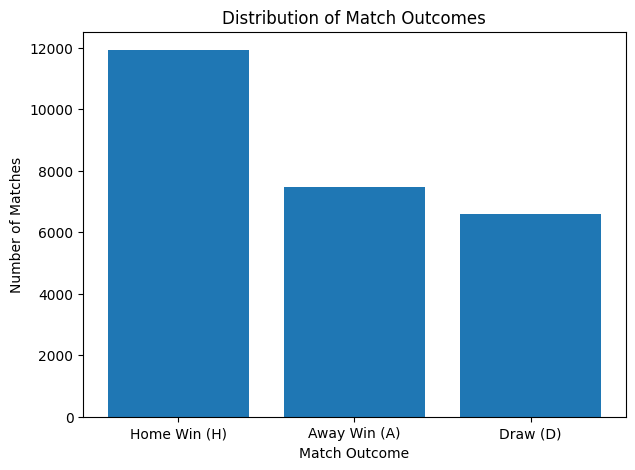

In [ ]:
outcome_counts = match_df["match_outcome"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Home Win (H)", "Away Win (A)", "Draw (D)"],
    [
        outcome_counts.get("H", 0),
        outcome_counts.get("A", 0),
        outcome_counts.get("D", 0)
    ]
)

plt.title("Distribution of Match Outcomes")
plt.xlabel("Match Outcome")
plt.ylabel("Number of Matches")

plt.show()

### 6.2 Home and Away Scoring Patterns

In [ ]:
home_avg = match_df["home_team_goal"].mean()
away_avg = match_df["away_team_goal"].mean()

print("Average home goals:", round(home_avg, 3))
print("Average away goals:", round(away_avg, 3))
print("Difference:", round(home_avg - away_avg, 3))

Average home goals: 1.545
Average away goals: 1.161
Difference: 0.384


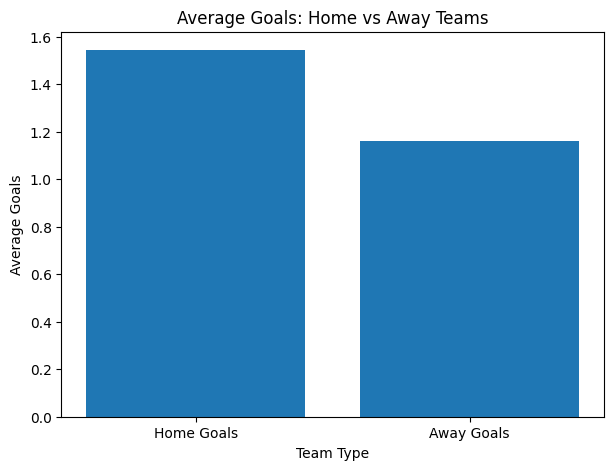

In [ ]:
labels = ["Home Goals", "Away Goals"]
values = [home_avg, away_avg]

plt.figure(figsize=(7, 5))

plt.bar(labels, values)

plt.title("Average Goals: Home vs Away Teams")
plt.xlabel("Team Type")
plt.ylabel("Average Goals")

plt.show()

In [ ]:
print("Home goal distribution:")
print(match_df["home_team_goal"].describe())

print("\nAway goal distribution:")
print(match_df["away_team_goal"].describe())

Home goal distribution:
count    25979.000000
mean         1.544594
std          1.297158
min          0.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         10.000000
Name: home_team_goal, dtype: float64

Away goal distribution:
count    25979.000000
mean         1.160938
std          1.142110
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max          9.000000
Name: away_team_goal, dtype: float64


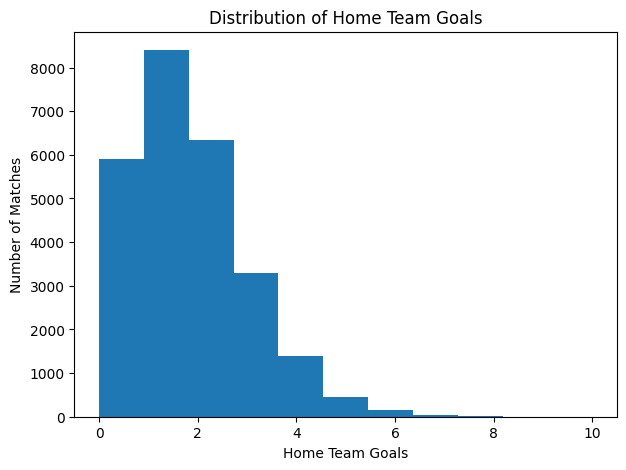

In [ ]:
plt.figure(figsize=(7, 5))

plt.hist(match_df["home_team_goal"], bins=11)

plt.title("Distribution of Home Team Goals")
plt.xlabel("Home Team Goals")
plt.ylabel("Number of Matches")

plt.show()

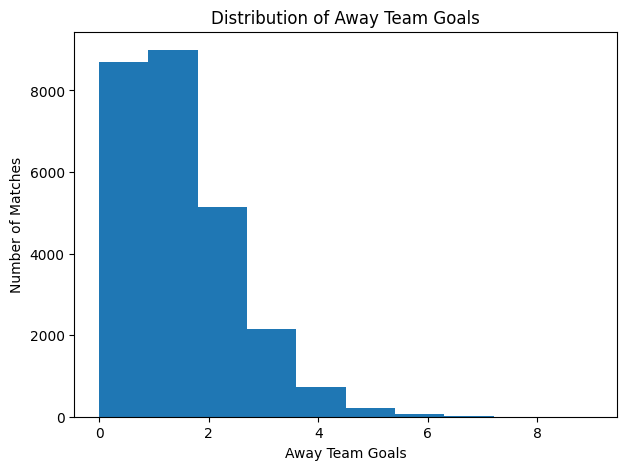

In [ ]:
plt.figure(figsize=(7, 5))

plt.hist(match_df["away_team_goal"], bins=10)

plt.title("Distribution of Away Team Goals")
plt.xlabel("Away Team Goals")
plt.ylabel("Number of Matches")

plt.show()

In [ ]:
match_df["season"].value_counts().sort_index()

,count
season,
2008/2009,3326
2009/2010,3230
2010/2011,3260
2011/2012,3220
2012/2013,3260
2013/2014,3032
2014/2015,3325
2015/2016,3326


In [ ]:
season_outcomes = pd.crosstab(
    match_df["season"],
    match_df["match_outcome"],
    normalize="index"
) * 100

season_outcomes.round(2)

match_outcome,A,D,H
season,,,
2008/2009,27.93,24.98,47.08
2009/2010,27.37,25.20,47.43
2010/2011,27.64,25.74,46.63
2011/2012,28.07,25.40,46.52
2012/2013,29.54,26.17,44.29
2013/2014,29.42,24.27,46.31
2014/2015,29.50,25.56,44.93
2015/2016,30.43,25.71,43.87


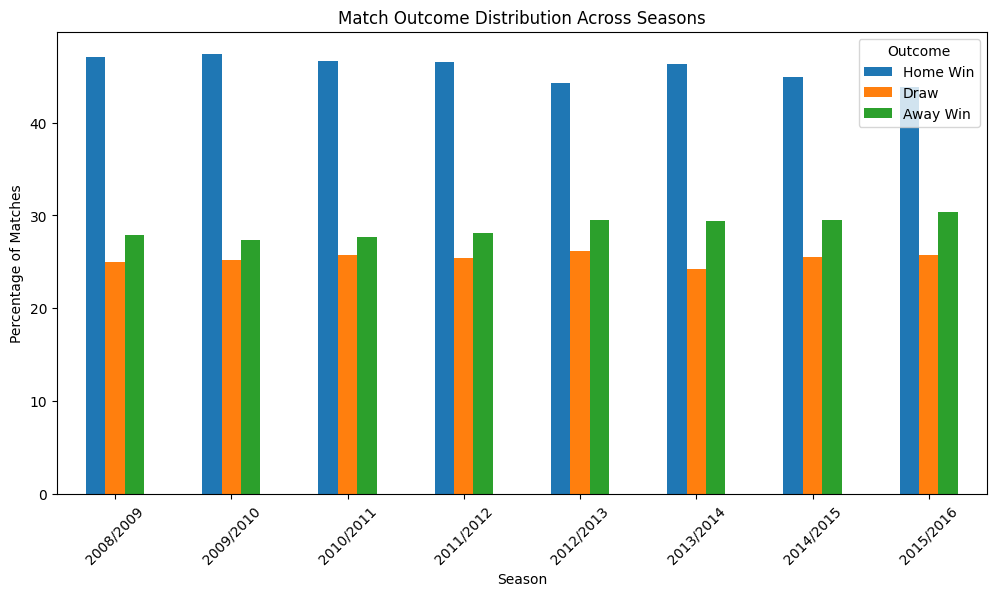

In [ ]:
season_outcomes[["H", "D", "A"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Match Outcome Distribution Across Seasons")
plt.xlabel("Season")
plt.ylabel("Percentage of Matches")
plt.xticks(rotation=45)

plt.legend(
    ["Home Win", "Draw", "Away Win"],
    title="Outcome"
)

plt.show()

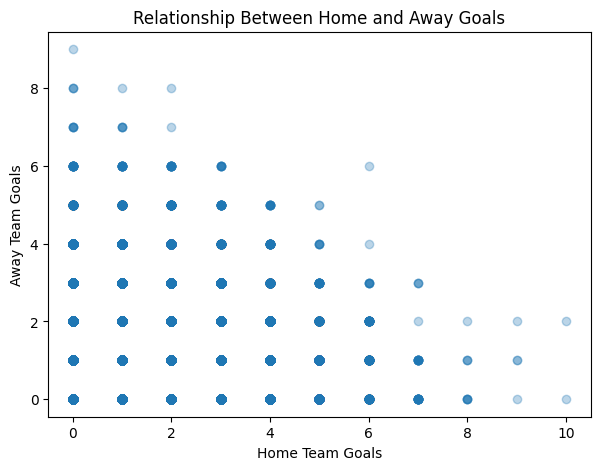

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    match_df["home_team_goal"],
    match_df["away_team_goal"],
    alpha=0.3
)

plt.title("Relationship Between Home and Away Goals")
plt.xlabel("Home Team Goals")
plt.ylabel("Away Team Goals")

plt.show()

### 6.3 EDA and Predictive Feature Separation

In [ ]:
match_df["stage"].value_counts().sort_index()

,count
stage,
1,740
2,740
3,740
4,740
5,740
6,740
7,738
8,738
9,738


In [ ]:
stage_outcomes = pd.crosstab(
    match_df["stage"],
    match_df["match_outcome"],
    normalize="index"
) * 100

stage_outcomes.round(2)

match_outcome,A,D,H
stage,,,
1,29.73,28.38,41.89
2,28.51,26.62,44.86
3,28.78,28.78,42.43
4,27.03,26.76,46.22
5,30.00,25.27,44.73
6,29.05,26.49,44.46
7,26.15,26.56,47.29
8,28.18,24.53,47.29
9,29.81,24.25,45.93


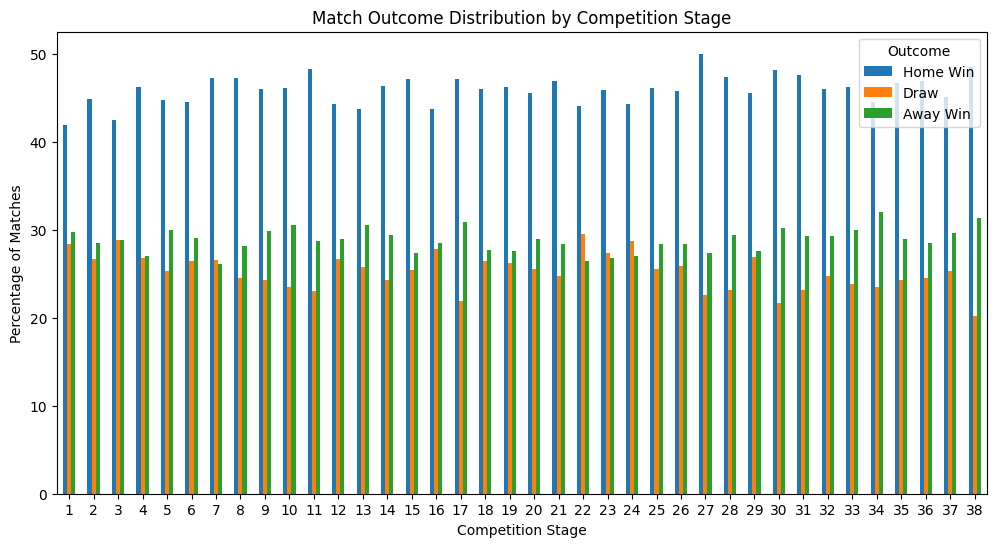

In [ ]:
stage_outcomes[["H", "D", "A"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Match Outcome Distribution by Competition Stage")
plt.xlabel("Competition Stage")
plt.ylabel("Percentage of Matches")
plt.xticks(rotation=0)

plt.legend(
    ["Home Win", "Draw", "Away Win"],
    title="Outcome"
)

plt.show()

In [ ]:
home_win_rate = (
    (match_df["match_outcome"] == "H").mean() * 100
)

away_win_rate = (
    (match_df["match_outcome"] == "A").mean() * 100
)

draw_rate = (
    (match_df["match_outcome"] == "D").mean() * 100
)

print("Home win rate:", round(home_win_rate, 2), "%")
print("Away win rate:", round(away_win_rate, 2), "%")
print("Draw rate:", round(draw_rate, 2), "%")

Home win rate: 45.87 %
Away win rate: 28.74 %
Draw rate: 25.39 %


In [ ]:
league_match_counts = match_df["league_id"].value_counts().sort_values(
    ascending=False
)

league_match_counts.head(15)

,count
league_id,
1729,3040
4769,3040
21518,3040
10257,3017
13274,2448
7809,2448
17642,2052
15722,1920
19694,1824


In [ ]:
league_outcomes = pd.crosstab(
    match_df["league_id"],
    match_df["match_outcome"],
    normalize="index"
) * 100

league_outcomes.round(2)

match_outcome,A,D,H
league_id,,,
1,28.53,24.59,46.88
1729,28.52,25.76,45.72
4769,27.04,28.26,44.70
7809,30.39,24.39,45.22
10257,26.98,26.38,46.64
13274,28.43,23.73,47.83
15722,27.34,27.34,45.31
17642,29.78,25.97,44.25
19694,33.83,24.51,41.67


### EDA Insight - Competition Differences

In [ ]:
unique_home_teams = match_df["home_team_api_id"].nunique()
unique_away_teams = match_df["away_team_api_id"].nunique()

print("Unique home teams:", unique_home_teams)
print("Unique away teams:", unique_away_teams)

Unique home teams: 299
Unique away teams: 299


In [ ]:
all_teams = pd.concat([
    match_df["home_team_api_id"],
    match_df["away_team_api_id"]
])

print("Unique teams appearing in matches:", all_teams.nunique())

Unique teams appearing in matches: 299


In [ ]:
home_team_counts = match_df["home_team_api_id"].value_counts()
away_team_counts = match_df["away_team_api_id"].value_counts()

team_match_counts = (
    home_team_counts.add(away_team_counts, fill_value=0)
    .sort_values(ascending=False)
)

team_match_counts.head(10)

,count
10194,304
9941,304
9938,304
8302,304
8305,304
8315,304
9927,304
9906,304
9925,304
8485,304


### 6.4 Pre-Match Bookmaker Odds vs Match Outcome

Matches with B365 odds: 22592 of 25979

Average implied probability by actual outcome:
                  pH     pD     pA
match_outcome                     
A              0.355  0.265  0.380
D              0.432  0.268  0.300
H              0.521  0.248  0.232

Accuracy of always picking the bookmaker favourite: 0.5333
Share of matches where the favourite is:  {'H': 0.726, 'A': 0.272, 'D': 0.001}


/tmp/ipykernel_2164/1405927088.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([odds_df.loc[odds_df.match_outcome == o, "B365H"] for o in order], labels=["Away win", "Draw", "Home win"])
/tmp/ipykernel_2164/1405927088.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([odds_df.loc[odds_df.match_outcome == o, "pH"] for o in order], labels=["Away win", "Draw", "Home win"])


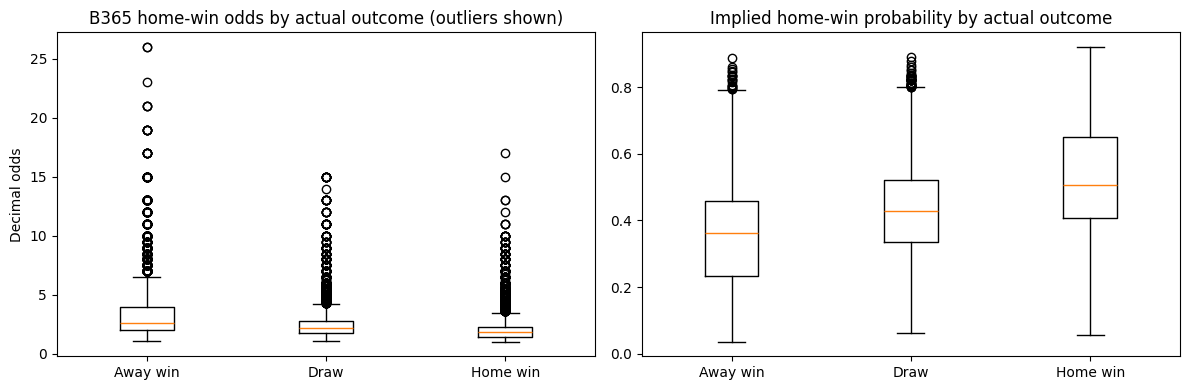


Skewness of B365H: 3.54


In [ ]:
odds_df = match_df.dropna(subset=["B365H", "B365D", "B365A"]).copy()
raw = 1 / odds_df[["B365H", "B365D", "B365A"]]
prob = raw.div(raw.sum(axis=1), axis=0)
prob.columns = ["pH", "pD", "pA"]
odds_df = pd.concat([odds_df, prob], axis=1)

print("Matches with B365 odds:", len(odds_df), "of", len(match_df))
print("\nAverage implied probability by actual outcome:")
print(odds_df.groupby("match_outcome")[["pH", "pD", "pA"]].mean().round(3))

favourite = np.array(["H", "D", "A"])[odds_df[["B365H", "B365D", "B365A"]].values.argmin(axis=1)]
print("\nAccuracy of always picking the bookmaker favourite:", round((favourite == odds_df.match_outcome).mean(), 4))
print("Share of matches where the favourite is: ", pd.Series(favourite).value_counts(normalize=True).round(3).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = ["A", "D", "H"]
axes[0].boxplot([odds_df.loc[odds_df.match_outcome == o, "B365H"] for o in order], labels=["Away win", "Draw", "Home win"])
axes[0].set_title("B365 home-win odds by actual outcome (outliers shown)")
axes[0].set_ylabel("Decimal odds")
axes[1].boxplot([odds_df.loc[odds_df.match_outcome == o, "pH"] for o in order], labels=["Away win", "Draw", "Home win"])
axes[1].set_title("Implied home-win probability by actual outcome")
plt.tight_layout()
plt.show()

print("\nSkewness of B365H:", round(odds_df.B365H.skew(), 2))

## 10. Data Quality and Preprocessing

### Step 1: leakage audit + first quality checks

In [ ]:
# 1) Group the columns by "when do we know this?"
odds_books = ["B365","BW","IW","LB","PS","WH","SJ","VC","GB","BS"]
groups = {
    "Post-match (LEAK)":   ["home_team_goal","away_team_goal"],
    "During-match (LEAK)": ["goal","shoton","shotoff","foulcommit",
                            "card","cross","corner","possession"],
    "Betting odds":        [b + s for b in odds_books for s in "HDA"],
    "Line-up player IDs":  [f"{side}_player_{i}" for side in ["home","away"]
                            for i in range(1, 12)],
    "Line-up X/Y coords":  [c for c in match_df.columns
                            if "player_X" in c or "player_Y" in c],
}

In [ ]:
# 2) How much is missing in each group?
audit = pd.DataFrame({
    g: {"columns": len(c),
        "avg % missing": round(match_df[c].isna().mean().mean() * 100, 1)}
    for g, c in groups.items()
}).T
print(audit)

                     columns  avg % missing
Post-match (LEAK)        2.0            0.0
During-match (LEAK)      8.0           45.3
Betting odds            30.0           26.1
Line-up player IDs      22.0            5.1
Line-up X/Y coords      44.0            7.0


In [ ]:
# 3) Duplicate and date checks
match_df["date"] = pd.to_datetime(match_df["date"])
print("Duplicate (date, home, away):",
      match_df.duplicated(["date","home_team_api_id","away_team_api_id"]).sum())
print("Date range:", match_df["date"].min().date(), "to", match_df["date"].max().date())

Duplicate (date, home, away): 0
Date range: 2008-07-18 to 2016-05-25


### Step 2: Missing Value Analysis and Treatment

In [ ]:
# Step 2A: which league has no odds?
league = pd.read_sql("SELECT id AS league_id, name AS league FROM League", conn)
tmp = match_df.merge(league, on="league_id")
print((tmp.groupby("league")["B365H"]
          .apply(lambda s: s.isna().mean() * 100)
          .round(1).sort_values(ascending=False)))

league
Poland Ekstraklasa          100.0
Switzerland Super League    100.0
Belgium Jupiler League        1.3
Portugal Liga ZON Sagres      0.4
Italy Serie A                 0.2
Netherlands Eredivisie        0.1
France Ligue 1                0.1
England Premier League        0.0
Germany 1. Bundesliga         0.0
Scotland Premier League       0.0
Spain LIGA BBVA               0.0
Name: B365H, dtype: float64


In [ ]:
# Step 2A-ii: why keep only B365? Compare the six full-coverage bookmakers
bk = ["B365", "BW", "IW", "LB", "WH", "VC"]
sub_ = match_df[[b + "H" for b in bk]]
summary = pd.DataFrame({
    "% missing": sub_.isna().mean().mul(100).round(1),
    "missing in same rows as B365 (%)": [round((sub_[c].isna() == sub_["B365H"].isna()).mean() * 100, 2) for c in sub_.columns],
})
complete = sub_.dropna()
summary["correlation with B365H"] = [round(complete[c].corr(complete["B365H"]), 3) for c in sub_.columns]
summary

,% missing,missing in same rows as B365 (%),correlation with B365H
B365H,13.0,100.00,1.000
BWH,13.1,99.91,0.987
IWH,13.3,99.69,0.980
LBH,13.2,99.84,0.985
WHH,13.1,99.90,0.986
VCH,13.1,99.89,0.988


In [ ]:
# Step 2B: build the model table
drop_leak  = groups["Post-match (LEAK)"] + groups["During-match (LEAK)"]
drop_xy    = groups["Line-up X/Y coords"]
odds_keep  = ["B365H", "B365D", "B365A"]
drop_odds  = [c for c in groups["Betting odds"] if c not in odds_keep]

model_df = match_df.drop(columns=drop_leak + drop_xy + drop_odds + ["id"]).copy()

print("Columns before:", match_df.shape[1], "| after:", model_df.shape[1])
print(model_df.isna().sum()[lambda s: s > 0])   # what's still missing

Columns before: 116 | after: 34
home_player_1     1224
home_player_2     1315
home_player_3     1281
home_player_4     1323
home_player_5     1316
home_player_6     1325
home_player_7     1227
home_player_8     1309
home_player_9     1273
home_player_10    1436
home_player_11    1555
away_player_1     1234
away_player_2     1278
away_player_3     1293
away_player_4     1321
away_player_5     1335
away_player_6     1313
away_player_7     1235
away_player_8     1341
away_player_9     1328
away_player_10    1441
away_player_11    1554
B365H             3387
B365D             3387
B365A             3387
dtype: int64


### Step 3: Data Consistency Checks and Categorical Encoding

In [ ]:
# 3A: consistency checks
team   = pd.read_sql("SELECT team_api_id FROM Team", conn)
player = pd.read_sql("SELECT player_api_id FROM Player", conn)
ids = [f"{s}_player_{i}" for s in ["home","away"] for i in range(1,12)]

print("Teams not in Team table:",
      (~model_df.home_team_api_id.isin(team.team_api_id)).sum()
      + (~model_df.away_team_api_id.isin(team.team_api_id)).sum())

all_players = pd.Series(model_df[ids].values.ravel()).dropna()
print("Player IDs not in Player table:", (~all_players.isin(player.player_api_id)).sum())

dup_players = model_df[ids].apply(lambda r: r.dropna().duplicated().any(), axis=1).sum()
print("Matches with a repeated player ID:", dup_players)

print("country_id <-> league_id 1-to-1:",
      model_df.groupby("league_id").country_id.nunique().max() == 1)

o = model_df.dropna(subset=["B365H"])
margin = 1/o.B365H + 1/o.B365D + 1/o.B365A
print("Implied probability sum: min %.3f, median %.3f, max %.3f"
      % (margin.min(), margin.median(), margin.max()))

Teams not in Team table: 0
Player IDs not in Player table: 0
Matches with a repeated player ID: 13
country_id <-> league_id 1-to-1: True
Implied probability sum: min 1.017, median 1.063, max 1.126


In [ ]:
# 3B: encoding
from sklearn.preprocessing import LabelEncoder

encoded_df = model_df.drop(columns=["country_id"]).copy()       # duplicate of league
encoded_df = pd.get_dummies(encoded_df, columns=["league_id"],
                            prefix="league", dtype=int)          # one-hot, 11 leagues

le = LabelEncoder()
encoded_df["target"] = le.fit_transform(encoded_df["match_outcome"])
print(dict(zip(le.classes_, le.transform(le.classes_))))
print(encoded_df.shape)

{'A': np.int64(0), 'D': np.int64(1), 'H': np.int64(2)}
(25979, 44)


### Step 4: Leakage-Safe Train/Test Split and Numerical Variable Handling

In [ ]:
# 4A: time-based split
train_seasons = ["2008/2009","2009/2010","2010/2011",
                 "2011/2012","2012/2013","2013/2014"]
train_df = encoded_df[encoded_df["season"].isin(train_seasons)].copy()
test_df  = encoded_df[~encoded_df["season"].isin(train_seasons)].copy()

print("Train:", len(train_df), "| Test:", len(test_df))
print("Train dates:", train_df.date.min().date(), "to", train_df.date.max().date())
print("Test dates :", test_df.date.min().date(), "to", test_df.date.max().date())
print("Overlap:", len(set(train_df.match_api_id) & set(test_df.match_api_id)))
print(train_df.match_outcome.value_counts(normalize=True).round(3))
print(test_df.match_outcome.value_counts(normalize=True).round(3))
assert train_df.date.max() < test_df.date.min()

Train: 19328 | Test: 6651
Train dates: 2008-07-18 to 2014-05-18
Test dates : 2014-07-18 to 2016-05-25
Overlap: 0
match_outcome
H    0.464
A    0.283
D    0.253
Name: proportion, dtype: float64
match_outcome
H    0.444
A    0.300
D    0.256
Name: proportion, dtype: float64


In [ ]:
# 4B: odds -> implied probabilities (no learning from data, so safe before scaling)
def add_implied_prob(df):
    df = df.copy()
    raw = 1 / df[["B365H","B365D","B365A"]]
    prob = raw.div(raw.sum(axis=1), axis=0)
    df["prob_H"], df["prob_D"], df["prob_A"] = prob["B365H"], prob["B365D"], prob["B365A"]
    return df

train_df = add_implied_prob(train_df)
test_df  = add_implied_prob(test_df)

In [ ]:
# 4B-ii: rows with no B365 odds cannot get an implied probability
# (mostly Poland Ekstraklasa and Switzerland Super League, which have 100% missing odds).
# These rows are kept in train_df/test_df for the no-odds feature set, but they must be
# dropped before building the odds-based scaled table, since there is no real value to use.
print("Train rows missing B365 odds:", train_df["B365H"].isna().sum(), "of", len(train_df))
print("Test rows missing B365 odds:", test_df["B365H"].isna().sum(), "of", len(test_df))

train_odds = train_df.dropna(subset=["prob_H", "prob_D", "prob_A"]).copy()
test_odds  = test_df.dropna(subset=["prob_H", "prob_D", "prob_A"]).copy()

print("Train rows kept for odds model:", len(train_odds), "| dropped:", len(train_df) - len(train_odds))
print("Test rows kept for odds model:", len(test_odds), "| dropped:", len(test_df) - len(test_odds))

# 4C: scaling (learn from TRAIN only, using only rows that have odds)
from sklearn.preprocessing import StandardScaler
num_cols = ["stage", "prob_H", "prob_D", "prob_A"]

scaler = StandardScaler()
train_scaled = train_odds.copy()
test_scaled  = test_odds.copy()
train_scaled[num_cols] = scaler.fit_transform(train_odds[num_cols])   # fit + transform
test_scaled[num_cols]  = scaler.transform(test_odds[num_cols])        # transform ONLY

print(train_scaled[num_cols].describe().loc[["mean","std"]].round(2))

Train rows missing B365 odds: 2545 of 19328
Test rows missing B365 odds: 842 of 6651
Train rows kept for odds model: 16783 | dropped: 2545
Test rows kept for odds model: 5809 | dropped: 842
      stage  prob_H  prob_D  prob_A
mean   -0.0     0.0     0.0     0.0
std     1.0     1.0     1.0     1.0


In [ ]:
rs = encoded_df.sample(frac=0.25, random_state=42)
rt = encoded_df.drop(rs.index)
print("Random split: test matches dated before the last train match:",
      int((rs["date"] < rt["date"].max()).sum()), "of", len(rs))

Random split: test matches dated before the last train match: 6494 of 6495


### Step 5: Class Imbalance, Final Leakage Checklist and Handoff

In [ ]:
# 5A: class imbalance
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

counts = train_df["match_outcome"].value_counts()
print(counts)
print("Majority/minority ratio:", round(counts.max() / counts.min(), 2))

classes = np.array([0, 1, 2])
weights = compute_class_weight("balanced", classes=classes, y=train_df["target"])
class_weights = dict(zip(classes, weights.round(3)))
print("Class weights (A=0, D=1, H=2):", class_weights)

majority = train_df["target"].mode()[0]
print("Majority-class baseline accuracy on test:",
      round((test_df["target"] == majority).mean(), 3))

match_outcome
H    8964
A    5473
D    4891
Name: count, dtype: int64
Majority/minority ratio: 1.83
Class weights (A=0, D=1, H=2): {np.int64(0): np.float64(1.177), np.int64(1): np.float64(1.317), np.int64(2): np.float64(0.719)}
Majority-class baseline accuracy on test: 0.444


In [ ]:
# 5B: final leakage checklist
leak_cols = groups["Post-match (LEAK)"] + groups["During-match (LEAK)"]
checks = {
    "No post/during-match columns in train": not any(c in train_df.columns for c in leak_cols),
    "No post/during-match columns in test":  not any(c in test_df.columns for c in leak_cols),
    "All train matches before all test matches": train_df["date"].max() < test_df["date"].min(),
    "No match appears in both sets": len(set(train_df.match_api_id) & set(test_df.match_api_id)) == 0,
    "Scaler mean comes from train only": np.allclose(scaler.mean_, train_odds[num_cols].mean().values),
    "No missing odds remain in the scaled odds table": (train_scaled[num_cols].isna().sum().sum() == 0
        and test_scaled[num_cols].isna().sum().sum() == 0),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)

PASS - No post/during-match columns in train
PASS - No post/during-match columns in test
PASS - All train matches before all test matches
PASS - No match appears in both sets
PASS - Scaler mean comes from train only
PASS - No missing odds remain in the scaled odds table


In [ ]:
# 5C: feature sets and handoff
league_cols = [c for c in train_df.columns if c.startswith("league_")]
features_no_odds = ["stage"] + league_cols
features_with_odds = features_no_odds + ["prob_H", "prob_D", "prob_A"]
print("No-odds features:", len(features_no_odds), "| With-odds features:", len(features_with_odds))

# train_df / test_df: full rows, use for the no-odds feature set (no missing values from odds).
# train_odds / test_odds: rows with a real B365 odds value only, use for the with-odds feature set.
# train_scaled / test_scaled: train_odds / test_odds with stage + implied probabilities scaled.
train_df.to_csv("train_df.csv", index=False)
test_df.to_csv("test_df.csv", index=False)
train_odds.to_csv("train_odds.csv", index=False)
test_odds.to_csv("test_odds.csv", index=False)
train_scaled.to_csv("train_scaled.csv", index=False)
test_scaled.to_csv("test_scaled.csv", index=False)

No-odds features: 12 | With-odds features: 15


In [ ]:
try:
    from google.colab import files
    for f in ["train_df.csv", "test_df.csv", "train_odds.csv", "test_odds.csv",
              "train_scaled.csv", "test_scaled.csv"]:
        files.download(f)
except ImportError:
    print("Not running on Colab - CSV files are saved in the working directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Feature Engineering and Feature Selection

### 11.1 Copy of the Cleaned Data

In [ ]:
# Take a fresh copy of the cleaned match data (cleaning was done in Sections 5-10)
df_clean = match_df.copy()
print("Original match_df shape:", match_df.shape)
print("Feature engineering df_clean shape:", df_clean.shape)

Original match_df shape: (25979, 116)
Feature engineering df_clean shape: (25979, 116)


### 11.2 Feature Construction (Lec 4: creating new features from existing data)

In [ ]:
# Copy for feature engineering - the cleaned data stays untouched
df_fe = df_clean.copy()
df_fe = df_fe.sort_values(["date", "match_api_id"]).reset_index(drop=True)

# Step 1: one row per team per match (so we can follow each team over time)
home = df_fe[["match_api_id", "date", "season", "home_team_api_id", "home_team_goal", "away_team_goal"]].copy()
home.columns = ["match_api_id", "date", "season", "team", "goals_for", "goals_against"]
home["is_home"] = 1

away = df_fe[["match_api_id", "date", "season", "away_team_api_id", "away_team_goal", "home_team_goal"]].copy()
away.columns = ["match_api_id", "date", "season", "team", "goals_for", "goals_against"]
away["is_home"] = 0

team_games = pd.concat([home, away]).sort_values(["team", "date", "match_api_id"]).reset_index(drop=True)

# Step 2: points earned in each match (win = 3, draw = 1, loss = 0)
team_games["points"] = np.where(team_games.goals_for > team_games.goals_against, 3,
                        np.where(team_games.goals_for == team_games.goals_against, 1, 0))

# Step 3: form of the LAST 5 matches. shift(1) removes the current match, so only the past is used.
for col, new_name in [("points", "form_pts"), ("goals_for", "form_gf"), ("goals_against", "form_ga")]:
    team_games[new_name] = team_games.groupby("team")[col].transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# Step 4: average points per game so far in the current season (again only past matches)
team_games["season_ppg"] = team_games.groupby(["team", "season"])["points"].transform(
    lambda s: s.shift(1).expanding().mean())

# Step 5: bring the features back to the match table (one set for the home team, one for the away team)
form_cols = ["form_pts", "form_gf", "form_ga", "season_ppg"]
home_feat = team_games[team_games.is_home == 1][["match_api_id"] + form_cols].rename(
    columns={c: "home_" + c for c in form_cols})
away_feat = team_games[team_games.is_home == 0][["match_api_id"] + form_cols].rename(
    columns={c: "away_" + c for c in form_cols})
df_fe = df_fe.merge(home_feat, on="match_api_id").merge(away_feat, on="match_api_id")

# Step 6: difference features (home minus away) - they compare the two teams directly
for c in form_cols:
    df_fe["diff_" + c] = df_fe["home_" + c] - df_fe["away_" + c]

# Step 7: implied probabilities from the bookmaker odds
odds_cols = ["B365H", "B365D", "B365A"]
odds = df_fe[odds_cols].where(df_fe[odds_cols] > 0)
raw = 1 / odds
df_fe[["prob_H", "prob_D", "prob_A"]] = raw.div(raw.sum(axis=1), axis=0).to_numpy()

# Target: 0 = Away win, 1 = Draw, 2 = Home win
df_fe["target"] = df_fe["match_outcome"].map({"A": 0, "D": 1, "H": 2})
assert df_fe["target"].notna().all(), "Unexpected or missing match_outcome values were found."

history_cols = [p + c for c in form_cols for p in ("home_", "away_")] + ["diff_" + c for c in form_cols]
print("df_clean shape:", df_clean.shape, "->  df_fe shape:", df_fe.shape)
print("New history features:", history_cols)
df_fe[["date", "home_team_api_id"] + history_cols[:4]].head()

df_clean shape: (25979, 116) ->  df_fe shape: (25979, 132)
New history features: ['home_form_pts', 'away_form_pts', 'home_form_gf', 'away_form_gf', 'home_form_ga', 'away_form_ga', 'home_season_ppg', 'away_season_ppg', 'diff_form_pts', 'diff_form_gf', 'diff_form_ga', 'diff_season_ppg']


,date,home_team_api_id,home_form_pts,away_form_pts,home_form_gf,away_form_gf
0,2008-07-18,10192,NaN,NaN,NaN,NaN
1,2008-07-19,9930,NaN,NaN,NaN,NaN
2,2008-07-20,10199,NaN,NaN,NaN,NaN
3,2008-07-20,7955,NaN,NaN,NaN,NaN
4,2008-07-23,9931,3.0,NaN,2.0,NaN


### Leakage Check for the History Features

In [ ]:
# Simple leakage check: recompute home_form_pts by hand for 100 random matches and compare
rng = np.random.default_rng(1)
wrong = 0
for mid in rng.choice(df_fe.match_api_id.values, 100, replace=False):
    row = df_fe[df_fe.match_api_id == mid].iloc[0]
    # all earlier matches of the home team
    earlier = df_fe[(df_fe.date < row.date) &
                    ((df_fe.home_team_api_id == row.home_team_api_id) | (df_fe.away_team_api_id == row.home_team_api_id))]
    last5 = earlier.tail(5)
    points = []
    for r in last5.itertuples():
        if r.home_team_api_id == row.home_team_api_id:
            gf, ga = r.home_team_goal, r.away_team_goal
        else:
            gf, ga = r.away_team_goal, r.home_team_goal
        points.append(3 if gf > ga else 1 if gf == ga else 0)
    expected = np.mean(points) if points else np.nan
    if not (np.isnan(expected) and np.isnan(row.home_form_pts)) and not np.isclose(expected, row.home_form_pts):
        wrong += 1
print("Wrong values out of 100 matches:", wrong)

Wrong values out of 100 matches: 0


### 11.3 Feature Transformation (Lec 3 / Lec 4: log transformation)

Skewness of home odds before log: 3.54
Skewness of home odds after log : 1.18


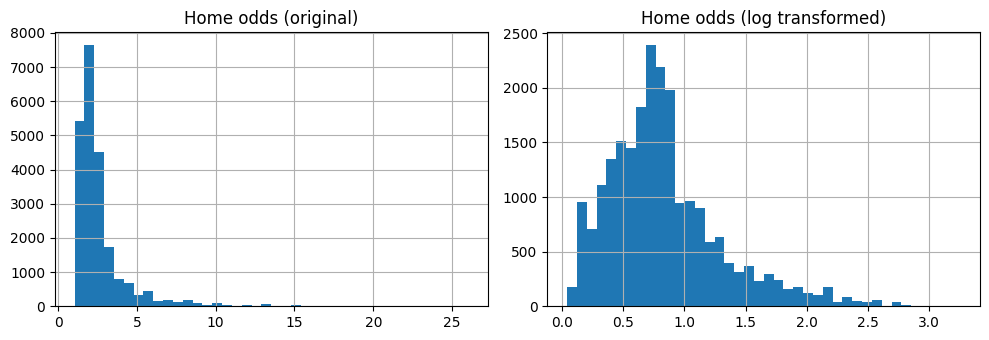

In [ ]:
# Feature transformation: odds are right-skewed, so apply a log transformation
for s in ["H", "D", "A"]:
    odds = df_fe["B365" + s].where(df_fe["B365" + s] > 0)
    df_fe["log_odds_" + s] = np.log(odds)

print("Skewness of home odds before log:", round(df_fe["B365H"].skew(), 2))
print("Skewness of home odds after log :", round(df_fe["log_odds_H"].skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df_fe["B365H"].hist(bins=40, ax=ax[0]); ax[0].set_title("Home odds (original)")
df_fe["log_odds_H"].hist(bins=40, ax=ax[1]); ax[1].set_title("Home odds (log transformed)")
plt.tight_layout()
plt.show()

### 11.4 Train / Test Split and Missing Values

In [ ]:
# Split the engineered table with the SAME train / test matches as before (time-based split)
fe_cols = history_cols + ["prob_H", "prob_D", "prob_A", "log_odds_H", "log_odds_D", "log_odds_A"]
keep = ["match_api_id", "date", "season", "match_outcome", "target"] + fe_cols

base_cols = ["match_api_id", "stage"] + league_cols
train_fe = train_df[base_cols].merge(df_fe[keep], on="match_api_id")
test_fe  = test_df[base_cols].merge(df_fe[keep], on="match_api_id")
print("train_fe:", train_fe.shape, "| test_fe:", test_fe.shape)

# Missing values in the history features = a team's very first matches (no history yet).
print("\nMissing values in history features (train, %):")
print(train_fe[history_cols].isna().mean().mul(100).round(1))

train_fe: (19328, 35) | test_fe: (6651, 35)

Missing values in history features (train, %):
home_form_pts      0.7
away_form_pts      0.7
home_form_gf       0.7
away_form_gf       0.7
home_form_ga       0.7
away_form_ga       0.7
home_season_ppg    2.8
away_season_ppg    2.9
diff_form_pts      0.9
diff_form_gf       0.9
diff_form_ga       0.9
diff_season_ppg    2.9
dtype: float64


In [ ]:
# Fill the history gaps with the TRAIN median (fit on train, apply to both)
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
train_fe[history_cols] = imputer.fit_transform(train_fe[history_cols])
test_fe[history_cols]  = imputer.transform(test_fe[history_cols])
print("Missing history values after imputation (train / test):",
      train_fe[history_cols].isna().sum().sum(), "/", test_fe[history_cols].isna().sum().sum())

Missing history values after imputation (train / test): 0 / 0


### 11.5 Feature Selection (Lec 4: filter, embedded and wrapper methods)

In [ ]:
# Separate copy for feature selection (only matches that have odds, so every feature can be compared)
df_sel = train_fe.dropna(subset=["prob_H"]).copy()
print("train_fe shape:", train_fe.shape, "->  df_sel shape:", df_sel.shape)

sel_cols = ["stage"] + fe_cols               # candidate features
X_sel = df_sel[sel_cols]
y_sel = df_sel["target"]

train_fe shape: (19328, 35) ->  df_sel shape: (16783, 35)


Mutual information with the multiclass target (highest first):
prob_A             0.094
log_odds_H         0.092
log_odds_A         0.091
prob_H             0.085
diff_season_ppg    0.060
diff_form_gf       0.039
prob_D             0.029
diff_form_pts      0.027
away_season_ppg    0.024
home_season_ppg    0.024
dtype: float64


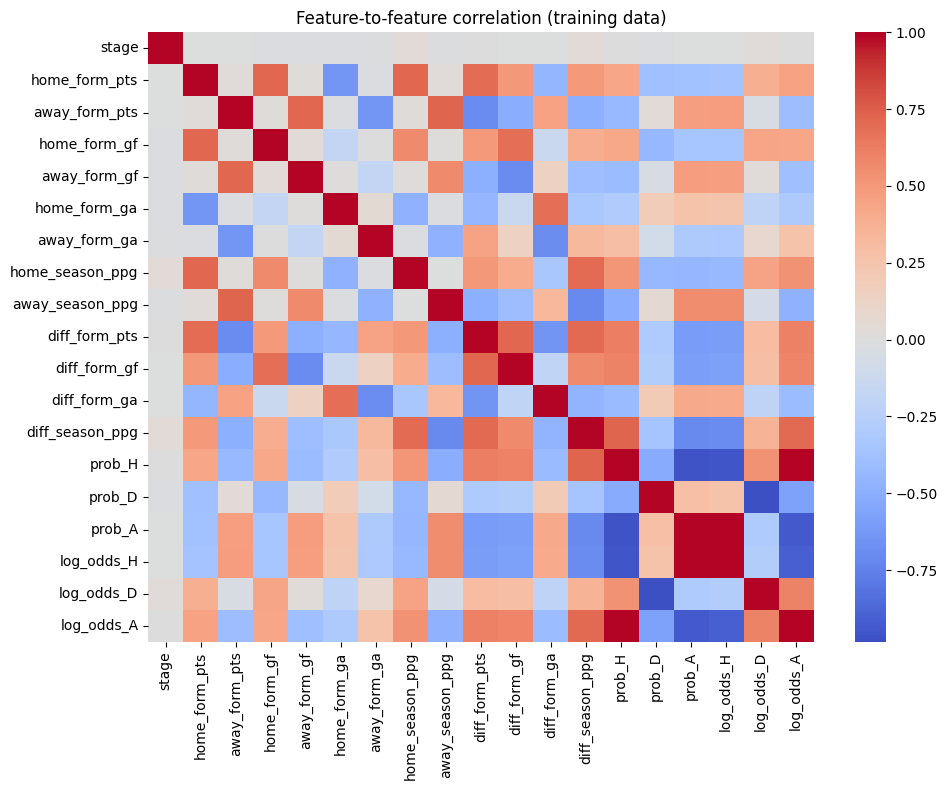

\nHighly correlated feature pairs (|r| > 0.90):
  prob_H & prob_A: r = -0.97
  prob_H & log_odds_H: r = -0.95
  prob_H & log_odds_A: r = 0.99
  prob_D & log_odds_D: r = -0.98
  prob_A & log_odds_H: r = 0.99
  prob_A & log_odds_A: r = -0.93
  log_odds_H & log_odds_A: r = -0.91


In [ ]:
# Filter method: use mutual information for the multiclass target,
# and Pearson correlation only to detect redundancy between input features.
from sklearn.feature_selection import mutual_info_classif

X_filter = df_sel[sel_cols].copy()
y_filter = df_sel["target"].astype(int)

mi_scores = mutual_info_classif(
    X_filter, y_filter, random_state=42
)
mi_scores = pd.Series(mi_scores, index=sel_cols).sort_values(ascending=False)

print("Mutual information with the multiclass target (highest first):")
print(mi_scores.round(3).head(10))

feature_corr = X_filter.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(feature_corr, cmap="coolwarm", center=0, annot=False)
plt.title("Feature-to-feature correlation (training data)")
plt.tight_layout()
plt.show()

# Pairs of features that may be redundant (|r| > 0.90)
print("\\nHighly correlated feature pairs (|r| > 0.90):")
for i, a in enumerate(sel_cols):
    for b in sel_cols[i + 1:]:
        value = feature_corr.loc[a, b]
        if pd.notna(value) and abs(value) > 0.90:
            print(f"  {a} & {b}: r = {value:.2f}")


prob_A             0.147
prob_H             0.133
log_odds_H         0.092
log_odds_A         0.087
diff_season_ppg    0.073
prob_D             0.063
away_season_ppg    0.057
home_season_ppg    0.056
stage              0.040
diff_form_pts      0.032
dtype: float64


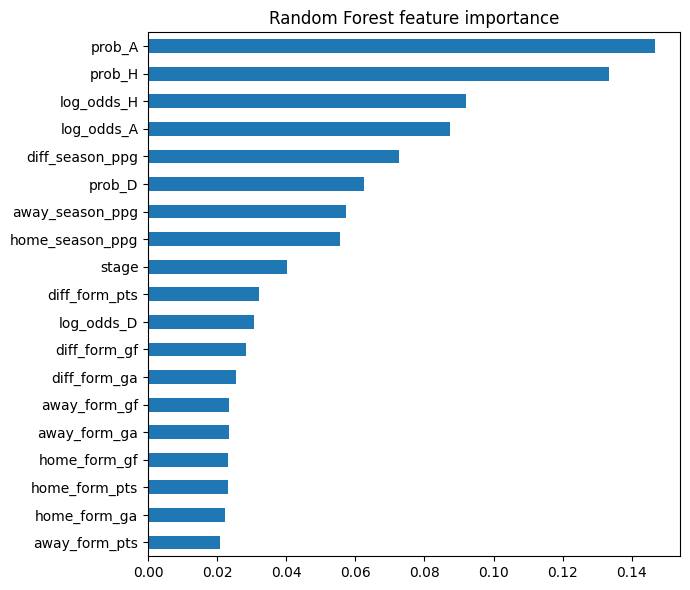

In [ ]:
# Embedded method: Random Forest feature importance
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1)
rf.fit(X_sel, y_sel)
importance = pd.Series(rf.feature_importances_, index=sel_cols).sort_values(ascending=False)
print(importance.round(3).head(10))

importance.sort_values().plot(kind="barh", figsize=(7, 6), title="Random Forest feature importance")
plt.tight_layout()
plt.show()

In [ ]:
# Wrapper method: Forward Feature Selection with Logistic Regression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit

df_sel = df_sel.sort_values(["date", "match_api_id"]).reset_index(drop=True)
y_sel = df_sel["target"].astype(int)  # labels are categorical classes, not continuous values
model = Pipeline([("scale", StandardScaler()), ("lr", LogisticRegression(max_iter=1000))])
sfs = SequentialFeatureSelector(model, n_features_to_select=6, direction="forward",
                                cv=TimeSeriesSplit(n_splits=3), scoring="accuracy")
sfs.fit(df_sel[sel_cols], df_sel["target"])
selected_forward = [c for c, keep_it in zip(sel_cols, sfs.get_support()) if keep_it]
print("Forward selection chose:", selected_forward)

Forward selection chose: ['away_form_ga', 'home_season_ppg', 'prob_H', 'prob_D', 'prob_A', 'log_odds_H']


### 11.6 Final Feature Set

In [ ]:
# Final feature sets (decision explained above)
history_final = ["diff_form_pts", "diff_form_gf", "diff_form_ga", "diff_season_ppg"]
final_no_odds   = ["stage"] + league_cols + history_final
final_with_odds = final_no_odds + ["prob_H", "prob_D"]      # prob_A is dropped: the three probabilities add up to 1

# Quick check inside the training data: fit on 2008-2013, validate on 2013/14 (test seasons untouched)
from sklearn.metrics import accuracy_score, f1_score

fit_part = df_sel[df_sel.season != "2013/2014"].copy()
val_part = df_sel[df_sel.season == "2013/2014"].copy()

if fit_part.empty or val_part.empty:
    raise ValueError("The chronological fit/validation split is empty. Check the season labels.")

def quick_eval(cols, name):
    m = Pipeline([("scale", StandardScaler()), ("lr", LogisticRegression(max_iter=1000, class_weight="balanced"))])
    m.fit(fit_part[cols], fit_part["target"])
    pred = m.predict(val_part[cols])
    return {"feature set": name, "features": len(cols),
            "accuracy": round(accuracy_score(val_part["target"], pred), 3),
            "macro F1": round(f1_score(val_part["target"], pred, average="macro"), 3)}

pd.DataFrame([
    quick_eval(["stage"] + league_cols, "Baseline (stage + league)"),
    quick_eval(["stage"] + league_cols + history_cols, "All 12 history features"),
    quick_eval(final_no_odds, "FINAL no-odds set"),
    quick_eval(final_with_odds, "FINAL with-odds set"),
    quick_eval(["prob_H", "prob_D"], "Odds only (reference)"),
])

,feature set,features,accuracy,macro F1
0,Baseline (stage + league),12,0.360,0.349
1,All 12 history features,24,0.486,0.450
2,FINAL no-odds set,16,0.491,0.451
3,FINAL with-odds set,18,0.499,0.472
4,Odds only (reference),2,0.491,0.469


### 11.7 Dimensionality Reduction with PCA

Explained variance ratio: [0.432 0.205 0.114 0.074 0.06  0.045 0.026 0.022 0.014 0.008 0.    0.
 0.    0.   ]
Cumulative explained variance: [0.432 0.637 0.751 0.825 0.885 0.929 0.955 0.977 0.991 1.    1.    1.
 1.    1.   ]


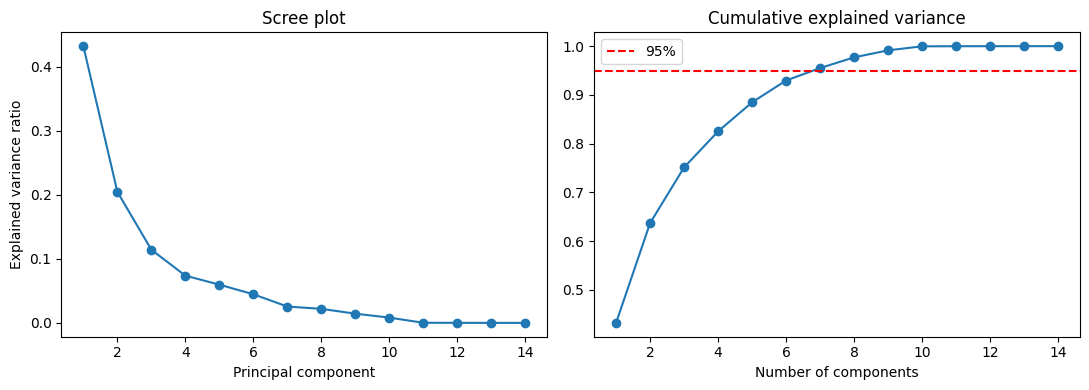

Original numeric features: 14
Components needed for 95% variance: 7
Dimensionality reduced by: 7
Shape before PCA: (16783, 14) | after PCA: (16783, 7)


In [ ]:
# PCA: standardize first, then check how much variance each component keeps
from sklearn.decomposition import PCA

pca_cols = history_cols + ["prob_H", "prob_D"]          # numeric features only
df_pca = df_sel[pca_cols].replace([np.inf, -np.inf], np.nan).dropna().copy()
if df_pca.empty:
    raise ValueError("No complete rows are available for PCA.")

scaler = StandardScaler()
X_std = scaler.fit_transform(df_pca)                              # PCA is affected by scale, so standardize

pca = PCA()
pca.fit(X_std)
ratio = pca.explained_variance_ratio_
cumulative = np.cumsum(ratio)

print("Explained variance ratio:", ratio.round(3))
print("Cumulative explained variance:", cumulative.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(ratio) + 1), ratio, marker="o")
ax[0].set_title("Scree plot"); ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("Explained variance ratio")
ax[1].plot(range(1, len(ratio) + 1), cumulative, marker="o")
ax[1].axhline(0.95, color="red", linestyle="--", label="95%")
ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("Number of components"); ax[1].legend()
plt.tight_layout()
plt.show()

n_95 = int(np.argmax(cumulative >= 0.95) + 1)
print("Original numeric features:", len(pca_cols))
print("Components needed for 95% variance:", n_95)
print("Dimensionality reduced by:", len(pca_cols) - n_95)

X_pca = PCA(n_components=n_95).fit_transform(X_std)
print("Shape before PCA:", X_std.shape, "| after PCA:", X_pca.shape)

### 11.8 Class Imbalance and Sampling

In [ ]:
# Class imbalance: how balanced is the target?
dist = train_fe["match_outcome"].value_counts()
print(pd.DataFrame({"matches": dist, "percentage": (dist / dist.sum() * 100).round(1)}))

# Random split vs stratified split
from sklearn.model_selection import train_test_split
_, test_rand = train_test_split(train_fe, test_size=0.25, random_state=7)
_, test_strat = train_test_split(train_fe, test_size=0.25, random_state=7, stratify=train_fe["target"])
print("\nClass share (%) in the test part:")
print(pd.DataFrame({"Original": train_fe["match_outcome"].value_counts(normalize=True) * 100,
                    "Random split": test_rand["match_outcome"].value_counts(normalize=True) * 100,
                    "Stratified split": test_strat["match_outcome"].value_counts(normalize=True) * 100}).round(1))

               matches  percentage
match_outcome                     
H                 8964        46.4
A                 5473        28.3
D                 4891        25.3

Class share (%) in the test part:
               Original  Random split  Stratified split
match_outcome                                          
H                  46.4          46.6              46.4
A                  28.3          29.3              28.3
D                  25.3          24.2              25.3


In [ ]:
# Oversampling, undersampling and SMOTE - applied to the TRAINING part only
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

num_features = ["stage"] + history_final + ["prob_H", "prob_D"]     # numeric features (SMOTE needs numbers)
X_fit = fit_part[num_features].replace([np.inf, -np.inf], np.nan)
X_val = val_part[num_features].replace([np.inf, -np.inf], np.nan)
y_fit = fit_part["target"].astype(int)
y_val = val_part["target"].astype(int)

# These candidate inputs should already be imputed; fail clearly if any gaps remain.
assert X_fit.notna().all().all() and X_val.notna().all().all(), (
    "Missing values remain in the sampling experiment features."
)

samplers = {"Original": None,
            "Random oversampling": RandomOverSampler(random_state=42),
            "Random undersampling": RandomUnderSampler(random_state=42),
            "SMOTE": SMOTE(random_state=42)}

rows = []
for name, sampler in samplers.items():
    X_res, y_res = (X_fit, y_fit) if sampler is None else sampler.fit_resample(X_fit, y_fit)
    m = Pipeline([("scale", StandardScaler()), ("lr", LogisticRegression(max_iter=1000))])
    m.fit(X_res, y_res)
    pred = m.predict(X_val)
    draw_recall = ((pred == 1) & (y_val == 1)).sum() / (y_val == 1).sum()
    rows.append({"approach": name, "training size": len(y_res),
                 "accuracy": round(accuracy_score(y_val, pred), 3),
                 "macro F1": round(f1_score(y_val, pred, average="macro"), 3),
                 "draw recall": round(draw_recall, 3),
                 "class counts": dict(pd.Series(y_res).value_counts().sort_index())})
pd.DataFrame(rows)

,approach,training size,accuracy,macro F1,draw recall,class counts
0,Original,14184,0.548,0.397,0.000,"{0: 3982, 1: 3627, 2: 6575}"
1,Random oversampling,19725,0.491,0.467,0.305,"{0: 6575, 1: 6575, 2: 6575}"
2,Random undersampling,10881,0.487,0.465,0.316,"{0: 3627, 1: 3627, 2: 3627}"
3,SMOTE,19725,0.489,0.466,0.313,"{0: 6575, 1: 6575, 2: 6575}"


### 11.9 Final Tables and Checks

In [ ]:
# Final checks and export (the data is NOT scaled - scale inside a Pipeline when modelling)
train_final = train_fe[["match_api_id", "date", "season", "match_outcome", "target"] + final_with_odds].copy()
test_final  = test_fe[["match_api_id", "date", "season", "match_outcome", "target"] + final_with_odds].copy()
train_final_odds = train_final.dropna(subset=["prob_H"])
test_final_odds  = test_final.dropna(subset=["prob_H"])

print("No missing values (no-odds features):",
      train_final[final_no_odds].isna().sum().sum() == 0 and test_final[final_no_odds].isna().sum().sum() == 0)
print("All train matches before test matches:", train_final.date.max() < test_final.date.min())
print("Target not used as a feature:", "target" not in final_with_odds and "match_outcome" not in final_with_odds)
print("\nNo-odds tables  :", train_final.shape, test_final.shape)
print("With-odds tables:", train_final_odds.shape, test_final_odds.shape)

import json
for name, d in [("train_final", train_final), ("test_final", test_final),
                ("train_final_odds", train_final_odds), ("test_final_odds", test_final_odds)]:
    d.to_csv(name + ".csv", index=False)
json.dump({"features_no_odds": final_no_odds, "features_with_odds": final_with_odds},
          open("final_feature_sets.json", "w"), indent=2)

try:
    from google.colab import files
    for f in ["train_final.csv", "test_final.csv", "train_final_odds.csv", "test_final_odds.csv", "final_feature_sets.json"]:
        files.download(f)
except ImportError:
    print("Files saved in the working directory.")

No missing values (no-odds features): True
All train matches before test matches: True
Target not used as a feature: True

No-odds tables  : (19328, 23) (6651, 23)
With-odds tables: (16783, 23) (5809, 23)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>